# Day 18 — Machine Learning Model Evaluation
**Internship task:** Evaluate Day 17 regression and classification models on the **same synthetic datasets**, using an 80/20 test split (`random_state=42`). Produce comparison tables, confusion matrices, and ROC curves.

**Important:** All datasets are synthetic and results are educational; no real customer or property outcomes are implied.

**Reproducibility:** Run this notebook from the folder containing its two CSV files. No external downloads are needed.

## Metric reference
**Regression:** MAE = mean absolute error; MSE = mean squared error; RMSE = square root of MSE; R² = proportion of variation explained relative to predicting the test-set mean (can be negative). Lower errors and higher R² are generally better.

**Classification (positive class = churn, 1):** Accuracy = (TP+TN)/N; Precision = TP/(TP+FP); Recall = TP/(TP+FN); F1 = 2×Precision×Recall/(Precision+Recall). A confusion matrix lists TN, FP, FN, TP. ROC-AUC measures ranking across classification thresholds; 0.5 corresponds to random ranking and 1.0 to perfect ranking.

**Important:** ROC-AUC is calculated using predicted probabilities, **not** hard class labels. Evaluation occurs only on held-out test data; no preprocessing is fit on the test data.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve)
DATA_DIR = Path.cwd()
print('Data directory:', DATA_DIR)

Data directory: /mnt/data/Day18_Model_Evaluation


## 1. Regression: house prices

In [2]:
houses = pd.read_csv(DATA_DIR / 'house_prices_synthetic.csv')
print('Rows, columns:', houses.shape)
display(houses.head())
X_reg = houses.drop(columns=['Price_INR'])
y_reg = houses['Price_INR']
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42)
reg_models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree Regressor': DecisionTreeRegressor(max_depth=5, min_samples_leaf=5, random_state=42)
}
reg_rows = []
reg_predictions = {}
for name, model in reg_models.items():
    model.fit(X_reg_train, y_reg_train)
    pred = model.predict(X_reg_test)
    reg_predictions[name] = pred
    reg_rows.append({'Model': name, 'MAE_INR': mean_absolute_error(y_reg_test, pred),
                     'MSE_INR2': mean_squared_error(y_reg_test, pred),
                     'RMSE_INR': np.sqrt(mean_squared_error(y_reg_test, pred)),
                     'R2': r2_score(y_reg_test, pred)})
reg_comparison = pd.DataFrame(reg_rows).sort_values('RMSE_INR').reset_index(drop=True)
display(reg_comparison.round(4))
reg_comparison.to_csv(DATA_DIR / 'regression_evaluation_comparison.csv', index=False)

Rows, columns: (360, 5)


,Area_sqft,Bedrooms,Property_Age_Years,Distance_to_Center_km,Price_INR
0,2191,2,5,15.02,9982440
1,2435,3,5,18.91,12086427
2,702,1,27,14.75,1753712
3,828,2,4,10.57,4697339
4,1526,3,14,8.88,8080722


,Model,MAE_INR,MSE_INR2,RMSE_INR,R2
0,Linear Regression,542276.4077,4.856319e+11,696872.9565,0.9598
1,Decision Tree Regressor,665151.3696,6.716055e+11,819515.4081,0.9444


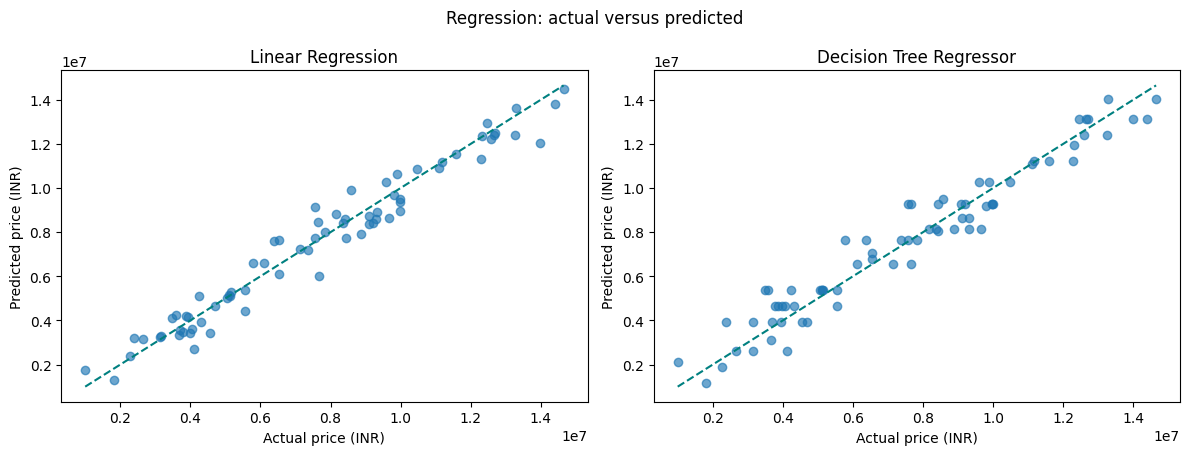

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (name, pred) in zip(axes, reg_predictions.items()):
    ax.scatter(y_reg_test, pred, alpha=0.65)
    low = min(y_reg_test.min(), pred.min()); high = max(y_reg_test.max(), pred.max())
    ax.plot([low, high], [low, high], linestyle='--', color='teal')
    ax.set(title=name, xlabel='Actual price (INR)', ylabel='Predicted price (INR)')
fig.suptitle('Regression: actual versus predicted')
plt.tight_layout()
plt.savefig(DATA_DIR / 'regression_actual_vs_predicted.png', dpi=160)
plt.show()

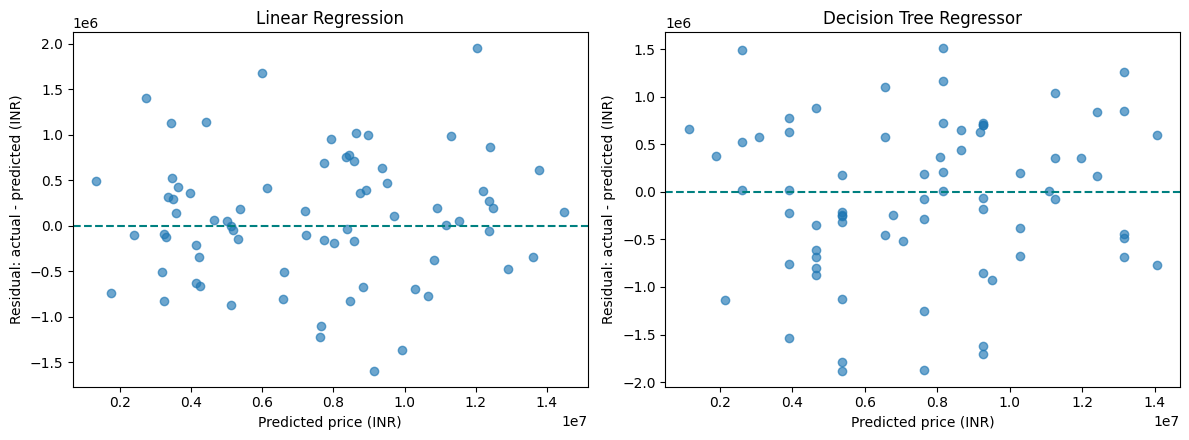

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, pred) in zip(axes, reg_predictions.items()):
    ax.scatter(pred, np.asarray(y_reg_test) - pred, alpha=0.65)
    ax.axhline(0, linestyle='--', color='teal')
    ax.set(title=name, xlabel='Predicted price (INR)', ylabel='Residual: actual - predicted (INR)')
plt.tight_layout()
plt.savefig(DATA_DIR / 'regression_residuals.png', dpi=160)
plt.show()

## 2. Classification: customer churn

In [5]:
customers = pd.read_csv(DATA_DIR / 'customer_churn_synthetic.csv')
print('Rows, columns:', customers.shape)
display(customers.head())
print('Target counts:'); display(customers['Churn'].value_counts())
X_clf = customers.drop(columns=['Churn'])
y_clf = customers['Churn']
X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=42, stratify=y_clf)
clf_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    'Random Forest Classifier': RandomForestClassifier(n_estimators=150, max_depth=7, min_samples_leaf=3, random_state=42)
}
clf_rows = []; clf_preds = {}; clf_probs = {}
for name, model in clf_models.items():
    model.fit(X_clf_train, y_clf_train)
    pred = model.predict(X_clf_test)
    prob = model.predict_proba(X_clf_test)[:, 1]
    clf_preds[name] = pred; clf_probs[name] = prob
    tn, fp, fn, tp = confusion_matrix(y_clf_test, pred, labels=[0, 1]).ravel()
    clf_rows.append({'Model': name, 'Accuracy': accuracy_score(y_clf_test, pred),
                     'Precision': precision_score(y_clf_test, pred, zero_division=0),
                     'Recall': recall_score(y_clf_test, pred, zero_division=0),
                     'F1': f1_score(y_clf_test, pred, zero_division=0),
                     'ROC_AUC': roc_auc_score(y_clf_test, prob),
                     'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
clf_comparison = pd.DataFrame(clf_rows).sort_values('ROC_AUC', ascending=False).reset_index(drop=True)
display(clf_comparison.round(4))
clf_comparison.to_csv(DATA_DIR / 'classification_evaluation_comparison.csv', index=False)

Rows, columns: (500, 6)


,Tenure_Months,Monthly_Charges_INR,Support_Calls_90_Days,Annual_Contract,Satisfaction_Score,Churn
0,36,860.06,2,0,1,1
1,48,2309.90,0,0,1,1
2,42,2386.31,3,1,2,1
3,62,1316.80,4,0,2,1
4,7,907.97,3,0,2,0


Target counts:


Churn
1    276
0    224
Name: count, dtype: int64

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,TN,FP,FN,TP
0,Logistic Regression,0.64,0.6667,0.6909,0.6786,0.7006,26,19,17,38
1,Random Forest Classifier,0.63,0.6552,0.6909,0.6726,0.6913,25,20,17,38


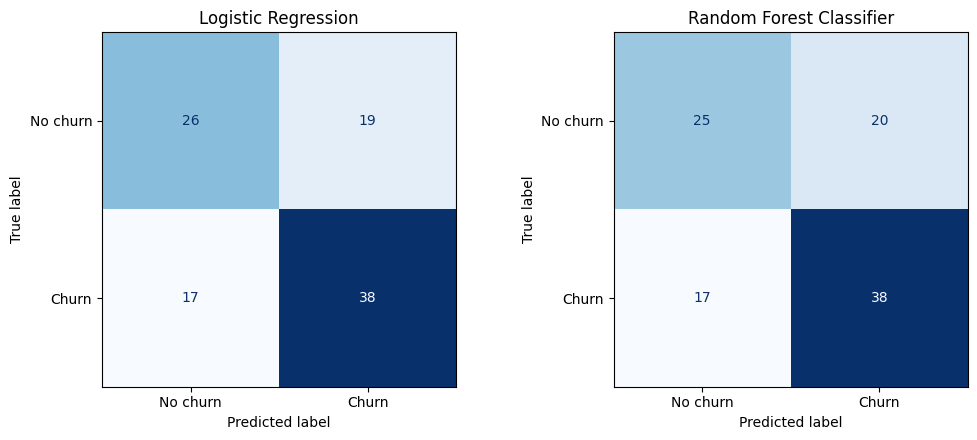

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.5))
for ax, (name, pred) in zip(axes, clf_preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_clf_test, pred, labels=[0, 1],
                                            display_labels=['No churn', 'Churn'],
                                            ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig(DATA_DIR / 'classification_confusion_matrices.png', dpi=160)
plt.show()

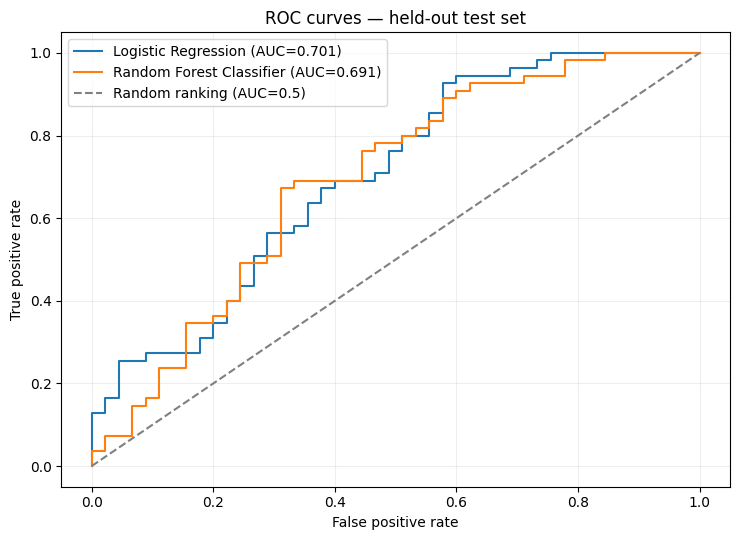

In [7]:
plt.figure(figsize=(7.5, 5.5))
for name, prob in clf_probs.items():
    fpr, tpr, thresholds = roc_curve(y_clf_test, prob)
    auc = roc_auc_score(y_clf_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Random ranking (AUC=0.5)')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('ROC curves — held-out test set')
plt.legend(); plt.grid(alpha=0.2); plt.tight_layout()
plt.savefig(DATA_DIR / 'classification_roc_curves.png', dpi=160)
plt.show()

## 3. Interpretation and limitations
- Regression: compare MAE/RMSE (lower) and R² (higher). RMSE penalizes large errors more than MAE.
- Classification: precision matters when false alarms are costly; recall matters when missing a churner is costly. Compare ROC-AUC for probability ranking, not just accuracy.
- The models use the **same Day 17 hyperparameters and splits**; only evaluation has been expanded.
- The results are based on one holdout split of **synthetic** data; they are not production estimates. For robust selection, later add cross-validation, calibration, and domain-specific costs.
- K-Means is not reevaluated here because the institute's Day 18 metric list concerns regression and classification; clustering was covered in Day 17.